# 09. Análise Relacional Entre Variáveis Contínuas (Métodos de Suavização)

## Objetivo

Explorar a relação não linear entre duas variáveis contínuas (**Volume Exportado/Importado em Milhões de Toneladas** vs. **Valor FOB em Milhões de US$**) utilizando **métodos de suavização não paramétricos**:

1. **KNN-Regressão** (Média móvel dos $k$ vizinhos mais próximos);
2. **Suavização por Núcleo / Kernel Smoothing** (Estimador de Nadaraya-Watson com Kernel Gaussiano e largura de banda $h$).

Estes métodos não supõem uma forma funcional rígida (como a reta OLS ou polinómios) e ajustam a previsão com base na vizinhança local do ponto de interesse.

## 0. Configurações e Carregamento dos Scripts e Dados

In [1]:
# Carrega as funções desenvolvidas no script em R
caminho_script <- file.path("..", "R", "analise_relacional_continuas.R")
if (!file.exists(caminho_script)) {
  caminho_script <- file.path("estrutura", "R", "analise_relacional_continuas.R")
}
source(caminho_script)

preparar_ambiente()
df_sazonal_lideres <- carregar_dados()

cat(sprintf("Base carregada com sucesso: %d observações.\n", nrow(df_sazonal_lideres)))


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘scales’


The following object is masked from ‘package:readr’:

    col_factor


ℹ Using "','" as decimal and "'.'" as grouping mark. Use `read_delim()` for more control.



Base carregada com sucesso: 481 observações.


## 1. Preparação da Base de Dados

Criamos as variáveis contínuas de interesse:
- `volume_mil_ton = Quilograma Líquido / 1e6`
- `valor_milhoes_fob = Valor US$ FOB / 1e6`

In [2]:
df_dados <- df_sazonal_lideres |>
  mutate(
    volume_mil_ton = `Quilograma Líquido` / 1e6,
    valor_milhoes_fob = `Valor US$ FOB` / 1e6
  ) |>
  filter(!is.na(volume_mil_ton) & !is.na(valor_milhoes_fob))

summary(df_dados[, c("volume_mil_ton", "valor_milhoes_fob")])

 volume_mil_ton  valor_milhoes_fob
 Min.   :  0.0   Min.   :  0.0    
 1st Qu.: 29.8   1st Qu.:  2.6    
 Median : 50.3   Median : 11.1    
 Mean   : 85.4   Mean   : 31.8    
 3rd Qu.: 87.8   3rd Qu.: 32.7    
 Max.   :756.7   Max.   :340.9    

## 2. Validação Cruzada (CV) para Escolha dos Hiperparâmetros

Avaliamos o erro de validação cruzada ($RMSE_{CV}$) para:
- **OLS Linear Simples** (baseline);
- **KNN-Regressão** variando o número de vizinhos $k$;
- **Kernel Smoothing** variando a largura de banda $h = c \cdot sd(X)$.

In [3]:
res_cv <- avaliar_modelos_cv(df_dados)

cat(sprintf("RMSE CV - OLS Reta Simples: %.4f\n\n", res_cv$rmse_ols))

cat("--- KNN Regressão (por k) ---\n")
print(res_cv$knn_cv)

cat("\n--- Kernel Smoothing (por h) ---\n")
print(res_cv$kernel_cv)

RMSE CV - OLS Reta Simples: 14.8430

--- KNN Regressão (por k) ---
   k RMSE_CV
1  3   14.64
2  5   14.85
3 10   15.14
4 15   15.50
5 20   16.12
6 40   20.56

--- Kernel Smoothing (por h) ---
       h h_mult RMSE_CV
1  5.331   0.05   14.27
2 10.662   0.10   13.95
3 21.324   0.20   15.04
4 42.649   0.40   16.89


## 3. Visualização e Comparação das Curvas de Suavização

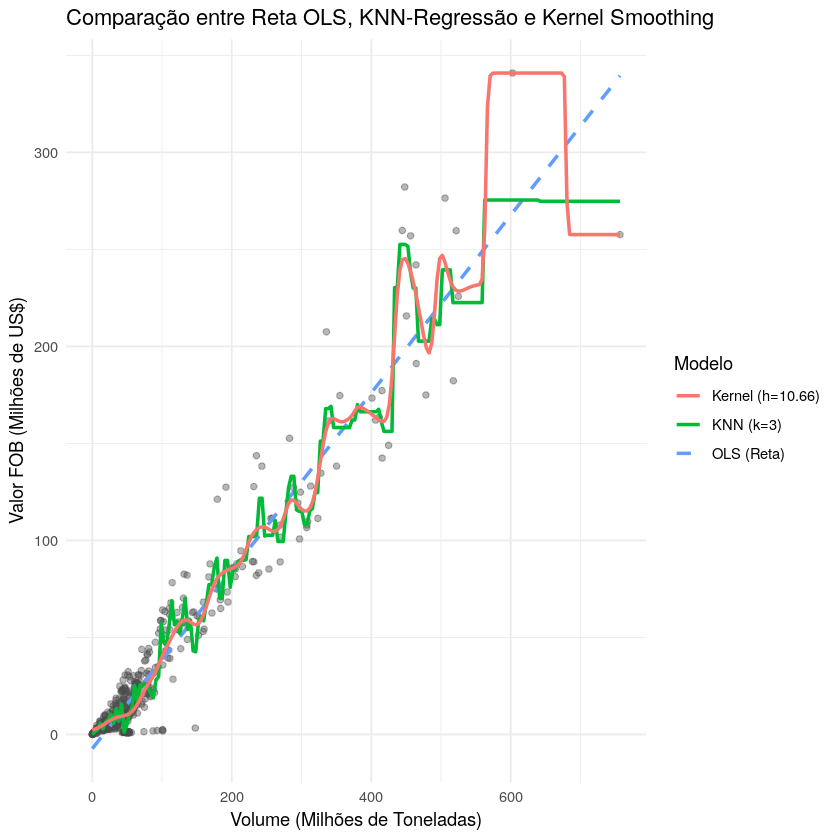

In [4]:
grid_x <- seq(min(df_dados$volume_mil_ton), max(df_dados$volume_mil_ton), length.out = 200)

# Melhor k e h encontrados via CV
melhor_k <- res_cv$knn_cv$k[which.min(res_cv$knn_cv$RMSE_CV)]
melhor_h <- res_cv$kernel_cv$h[which.min(res_cv$kernel_cv$RMSE_CV)]

# Predições sobre o grid
y_knn <- sapply(grid_x, knn_reg, x = df_dados$volume_mil_ton, y = df_dados$valor_milhoes_fob, k = melhor_k)
y_kernel <- sapply(grid_x, kernel_nw, x = df_dados$volume_mil_ton, y = df_dados$valor_milhoes_fob, h = melhor_h)

mod_ols <- lm(valor_milhoes_fob ~ volume_mil_ton, data = df_dados)
y_ols <- predict(mod_ols, newdata = data.frame(volume_mil_ton = grid_x))

df_grid <- tibble(
  volume_mil_ton = grid_x,
  OLS = y_ols,
  KNN = y_knn,
  Kernel = y_kernel
)

ggplot(df_dados, aes(x = volume_mil_ton, y = valor_milhoes_fob)) +
  geom_point(alpha = 0.4, color = "gray30") +
  geom_line(data = df_grid, aes(y = OLS, color = "OLS (Reta)"), linewidth = 1, linetype = "dashed") +
  geom_line(data = df_grid, aes(y = KNN, color = sprintf("KNN (k=%d)", melhor_k)), linewidth = 1) +
  geom_line(data = df_grid, aes(y = Kernel, color = sprintf("Kernel (h=%.2f)", melhor_h)), linewidth = 1) +
  labs(
    title = "Comparação entre Reta OLS, KNN-Regressão e Kernel Smoothing",
    x = "Volume (Milhões de Toneladas)",
    y = "Valor FOB (Milhões de US$)",
    color = "Modelo"
  ) +
  theme_minimal()

## 4. Conclusão

- A reta OLS pressupõe uma relação constante global entre volume e valor.
- Os métodos não paramétricos (**KNN** e **Kernel**) adaptam-se a mudanças locais de inclinação e variações de escala ao longo do eixo contínuo.
- O parâmetro de suavização ($k$ ou $h$) controla o *trade-off* viés-variância: valores muito pequenos produzem curvas rugosas (alta variância), enquanto valores muito grandes achatam o modelo em direção à média global (alto viés).